In [1]:
!pip install pandas numpy scikit-learn matplotlib seaborn joblib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
data = {
    "review": [
        "Excellent product, I am very happy with the quality.",
        "The delivery was fast and the product works perfectly.",
        "Amazing service and friendly customer support.",
        "I love this product and would recommend it.",
        "Very good quality for the price.",
        "The product exceeded my expectations.",
        "Great experience from ordering to delivery.",
        "Customer service solved my problem quickly.",
        "I am satisfied with my purchase.",
        "Fantastic product and excellent performance.",

        "The product is okay and works as expected.",
        "Delivery was on time and the package was normal.",
        "The quality is average for this price.",
        "The product is neither great nor bad.",
        "It works, but there is nothing special about it.",
        "The service was acceptable.",
        "The design is simple and functional.",
        "I received the product and it is fine.",
        "The battery performance is average.",
        "The product meets my basic requirements.",

        "Very disappointed with this purchase.",
        "The product stopped working after a few days.",
        "Customer service was slow and unhelpful.",
        "The delivery was late and the package was damaged.",
        "The quality is poor and not worth the money.",
        "I regret buying this product.",
        "The app crashes frequently and is frustrating.",
        "The product does not work as advertised.",
        "The battery drains very quickly.",
        "The packaging was damaged when it arrived."
    ],

    "sentiment": [
        "Positive", "Positive", "Positive", "Positive", "Positive",
        "Positive", "Positive", "Positive", "Positive", "Positive",

        "Neutral", "Neutral", "Neutral", "Neutral", "Neutral",
        "Neutral", "Neutral", "Neutral", "Neutral", "Neutral",

        "Negative", "Negative", "Negative", "Negative", "Negative",
        "Negative", "Negative", "Negative", "Negative", "Negative"
    ]
}

df = pd.DataFrame(data)

print("Dataset created successfully!")
print("Number of reviews:", len(df))

df.head()

Dataset created successfully!
Number of reviews: 30


,review,sentiment
0,"Excellent product, I am very happy with the qu...",Positive
1,The delivery was fast and the product works pe...,Positive
2,Amazing service and friendly customer support.,Positive
3,I love this product and would recommend it.,Positive
4,Very good quality for the price.,Positive


In [4]:
# Display dataset information

print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

Dataset Shape:
(30, 2)

Column Names:
['review', 'sentiment']

Missing Values:
review       0
sentiment    0
dtype: int64

Sentiment Distribution:
sentiment
Positive    10
Neutral     10
Negative    10
Name: count, dtype: int64


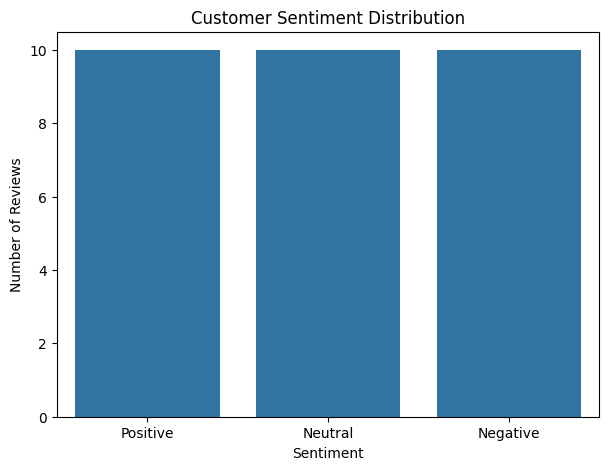

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="sentiment"
)

plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [6]:
# Input feature
X = df["review"]

# Target/output
y = df["sentiment"]

print("Input data:")
print(X.head())

print("\nTarget labels:")
print(y.head())

Input data:
0    Excellent product, I am very happy with the qu...
1    The delivery was fast and the product works pe...
2       Amazing service and friendly customer support.
3          I love this product and would recommend it.
4                     Very good quality for the price.
Name: review, dtype: object

Target labels:
0    Positive
1    Positive
2    Positive
3    Positive
4    Positive
Name: sentiment, dtype: object


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

print("\nTraining data:")
print(X_train.head())

Training reviews: 22
Testing reviews: 8

Training data:
6          Great experience from ordering to delivery.
16                The design is simple and functional.
26      The app crashes frequently and is frustrating.
11    Delivery was on time and the package was normal.
3          I love this product and would recommend it.
Name: review, dtype: object


In [8]:
# Create TF-IDF vectorizer
vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2)
)

# Learn from training data and transform it
X_train_tfidf = vectorizer.fit_transform(X_train)

# Transform testing data
X_test_tfidf = vectorizer.transform(X_test)

print("TF-IDF conversion completed!")

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

TF-IDF conversion completed!
Training data shape: (22, 104)
Testing data shape: (8, 104)


In [9]:
# Create the Logistic Regression model
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [10]:
# Predict sentiment for test data
y_pred = model.predict(X_test_tfidf)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", f"{accuracy:.2%}")

Model Accuracy: 37.50%


In [11]:
# Generate classification report
report = classification_report(
    y_test,
    y_pred,
    zero_division=0
)

print("Classification Report:")
print(report)

Classification Report:
              precision    recall  f1-score   support

    Negative       0.50      0.50      0.50         2
     Neutral       0.50      0.33      0.40         3
    Positive       0.25      0.33      0.29         3

    accuracy                           0.38         8
   macro avg       0.42      0.39      0.40         8
weighted avg       0.41      0.38      0.38         8



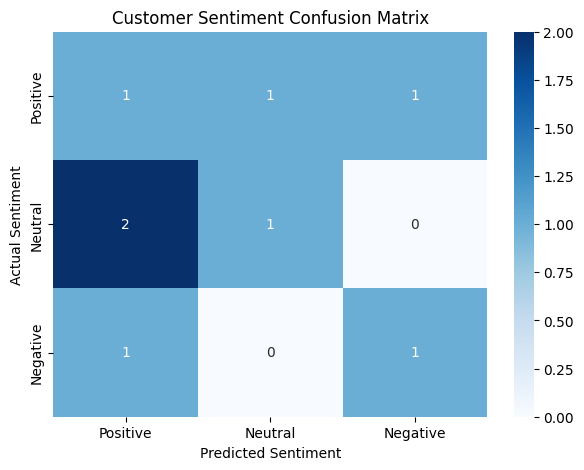

In [12]:
# Create confusion matrix
labels = ["Positive", "Neutral", "Negative"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

# Display confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Customer Sentiment Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()

In [13]:
def predict_sentiment(review):
    # Convert the new review into TF-IDF features
    review_tfidf = vectorizer.transform([review])

    # Predict sentiment
    prediction = model.predict(review_tfidf)[0]

    # Get confidence score
    confidence = model.predict_proba(review_tfidf).max()

    return prediction, confidence


# Test the function
review = "The product quality is excellent and I am very happy."

sentiment, confidence = predict_sentiment(review)

print("Review:", review)
print("Predicted Sentiment:", sentiment)
print("Confidence:", f"{confidence:.2%}")

Review: The product quality is excellent and I am very happy.
Predicted Sentiment: Positive
Confidence: 40.02%


In [14]:
test_reviews = [
    "The product is amazing and I really love it.",
    "The product is okay but nothing special.",
    "The delivery was very late and the product was damaged."
]

for review in test_reviews:
    sentiment, confidence = predict_sentiment(review)

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("Confidence:", f"{confidence:.2%}")
    print("-" * 60)

Review: The product is amazing and I really love it.
Predicted Sentiment: Positive
Confidence: 42.80%
------------------------------------------------------------
Review: The product is okay but nothing special.
Predicted Sentiment: Neutral
Confidence: 44.42%
------------------------------------------------------------
Review: The delivery was very late and the product was damaged.
Predicted Sentiment: Negative
Confidence: 48.18%
------------------------------------------------------------


In [15]:
# Get a review from the user
user_review = input("Enter a customer review: ")

# Predict sentiment
sentiment, confidence = predict_sentiment(user_review)

print("\nCustomer Review:")
print(user_review)

print("\nPredicted Sentiment:")
print(sentiment)

print("Model Confidence:")
print(f"{confidence:.2%}")

Enter a customer review: I really love this product. The quality is amazing!

Customer Review:
I really love this product. The quality is amazing!

Predicted Sentiment:
Positive
Model Confidence:
45.71%


In [16]:
# Save the trained model
joblib.dump(model, "customer_sentiment_model.pkl")

# Save the TF-IDF vectorizer
joblib.dump(vectorizer, "customer_sentiment_tfidf.pkl")

# Save the dataset
df.to_csv("customer_sentiment_dataset.csv", index=False)

print("All project files saved successfully!")
print("\nFiles created:")
print("1. customer_sentiment_model.pkl")
print("2. customer_sentiment_tfidf.pkl")
print("3. customer_sentiment_dataset.csv")

All project files saved successfully!

Files created:
1. customer_sentiment_model.pkl
2. customer_sentiment_tfidf.pkl
3. customer_sentiment_dataset.csv


In [17]:
print("==========================================")
print("   AI CUSTOMER SENTIMENT ANALYZER")
print("==========================================")
print("Type 'exit' to stop the analyzer.\n")

while True:
    user_review = input("Enter customer review: ")

    if user_review.lower() == "exit":
        print("\nSentiment analysis stopped.")
        break

    if user_review.strip() == "":
        print("Please enter a valid review.\n")
        continue

    sentiment, confidence = predict_sentiment(user_review)

    print("\nPredicted Sentiment:", sentiment)
    print("Confidence:", f"{confidence:.2%}")
    print("-" * 50)

   AI CUSTOMER SENTIMENT ANALYZER
Type 'exit' to stop the analyzer.

Enter customer review: The product is excellent and I am very satisfied.

Predicted Sentiment: Positive
Confidence: 47.14%
--------------------------------------------------
Enter customer review: exit

Sentiment analysis stopped.


In [18]:
print("==========================================")
print("   AI CUSTOMER SENTIMENT ANALYSIS")
print("==========================================")

print("\nProject Summary:")
print("• Dataset: Customer Reviews")
print("• Total Reviews:", len(df))
print("• Sentiment Classes: Positive, Neutral, Negative")
print("• Text Processing: TF-IDF")
print("• Machine Learning Algorithm: Logistic Regression")
print("• Evaluation: Accuracy, Classification Report, Confusion Matrix")
print("• Prediction: Real-time customer review sentiment")
print("• Platform: Google Colab")
print("• Language: Python")

print("\nProject completed successfully!")

   AI CUSTOMER SENTIMENT ANALYSIS

Project Summary:
• Dataset: Customer Reviews
• Total Reviews: 30
• Sentiment Classes: Positive, Neutral, Negative
• Text Processing: TF-IDF
• Machine Learning Algorithm: Logistic Regression
• Evaluation: Accuracy, Classification Report, Confusion Matrix
• Prediction: Real-time customer review sentiment
• Platform: Google Colab
• Language: Python

Project completed successfully!


In [19]:
import os

print("Project files:")
print("-" * 40)

files = [
    "customer_sentiment_model.pkl",
    "customer_sentiment_tfidf.pkl",
    "customer_sentiment_dataset.csv"
]

for file in files:
    if os.path.exists(file):
        size = os.path.getsize(file)
        print(f"✓ {file}  ({size} bytes)")
    else:
        print(f"✗ {file}  (Not found)")

Project files:
----------------------------------------
✓ customer_sentiment_model.pkl  (3535 bytes)
✓ customer_sentiment_tfidf.pkl  (3341 bytes)
✓ customer_sentiment_dataset.csv  (1531 bytes)


In [20]:
from google.colab import files

files.download("customer_sentiment_model.pkl")
files.download("customer_sentiment_tfidf.pkl")
files.download("customer_sentiment_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>